<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<h3 style="color:green;">0. Installiere die notwendigen Module, falls sie noch nicht installiert sind, und importiere die notwendigen Module</h3>


In [337]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import chi2_contingency
from pandas.api.types import is_numeric_dtype
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

In [338]:
"""
import warnings
warnings.filterwarnings("ignore")

import numpy as np


import seaborn as sns
import pyreadstat
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, make_scorer

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
"""

'\nimport warnings\nwarnings.filterwarnings("ignore")\n\nimport numpy as np\n\n\nimport seaborn as sns\nimport pyreadstat\nimport matplotlib.pyplot as plt\nfrom matplotlib.ticker import MaxNLocator\n\nfrom sklearn.model_selection import train_test_split, cross_val_score\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import OneHotEncoder\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.metrics import mean_squared_error, make_scorer\n\nimport statsmodels.api as sm\nfrom statsmodels.stats.outliers_influence import variance_inflation_factor\nfrom statsmodels.stats.diagnostic import het_breuschpagan\nfrom statsmodels.stats.stattools import jarque_bera\n'

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<h3 style="color:green;">1. Lese den Datensatz ein und lege ihn im Dataframe df ab</h3>

<p class="explanation">
<i>Lies den Datensatz von meiner lokalen Festplatte oder andernfalls von seiner URL ein</i>!
</p>

In [339]:
URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/"
       "data/Telco-Customer-Churn.csv")

BASE_DIR = Path.cwd() 
LOCAL_FILE = BASE_DIR/"Data"/"Telco-Customer-Churn.csv"


OUTPUT_Plots = BASE_DIR/"Plots"
REPORTS_FILES = BASE_DIR/"Reports"
#Path.home()/"PycharmProjects"/"BBQ"/"PCED-PCAD"

if LOCAL_FILE.exists():
    df = pd.read_csv(LOCAL_FILE)
else:
    df = pd.read_csv(URL)
    df.to_csv(LOCAL_FILE, index=False)

print("Datensatz erfolgreich geladen.")
print("Anzahl Zeilen und Spalten:", df.shape)
print("Originale Spalten:")
print(df.columns.tolist())
df.info()
df.head()

Datensatz erfolgreich geladen.
Anzahl Zeilen und Spalten: (7043, 21)
Originale Spalten:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   Intern

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


  <style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>
<h3 style="color:green;">2. Wir handeln die Features wie folgenden:</h3>

  <style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>
<div class="explanation">
<h4 style="color:green;"> 2.0 Entfernen von Duplikaten und von NaN</h4>
<ul>
  <li>
    Prüfe, ob der DataFrame doppelte /NaN Datensätze enthält, und entferne diese,
    falls vorhanden.
  </li>
</ul>

    

In [340]:
df_neue = df.copy().drop_duplicates()
df_neue.info()
df_neue.head()
print("Anzahl Zeilen und Spalten:", df_neue.shape)
df_neue = df_neue.dropna()
print("Anzahl Zeilen und Spalten:", df_neue.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<div class="explanation">
<h4 style="color:green;"> 2.1. Kundenidentität &amp; Demografie</h4>

  <ul>
    <li>
      <span class="code-orange">customerID:</span>
      Eine eindeutige ID für jeden Kunden,
      Es ist das Modell nicht sinnvoll – vor dem Training entfernen.
    </li>
  </ul>

In [341]:
df_neue = df_neue.drop(columns="customerID")
df_neue.info()
df_neue.head()
print("Anzahl Zeilen und Spalten:", df_neue.shape)
print(df_neue.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }

  .key-point {
    color: #6FBF9E;
  }

  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }

  .explanation {
    color: #B5ADC2;
  }
</style>

<div class="explanation">

<h4 style="color:green;">
    2.2. Das Merkmal <span class="code-orange">"TotalCharges"</span> wird als Objekt gespeichert, sollte jedoch numerisch sein.
</h4>
  <ul>
    <li>
      Wandle das Merkmal <span class="code-orange">"TotalCharges"</span>
      in einen numerischen Datentyp (<span class="code-orange">float</span>) um.
    </li>
    <li>
      Ermittle, wie viele Werte sich nicht in numerische Werte umwandeln lassen,
      und entferne gegebenenfalls die entsprechenden Datensätze.
    </li>
    <li>
      Mit <span class="code-orange">errors="coerce"</span> wird jeder Wert, der sich
      nicht in eine gültige Zahl umwandeln lässt, automatisch zu
      <span class="code-orange">NaN</span>. 
      Dazu gehören sowohl leere Einträge als
      auch textähnliche Datumsangaben.
    </li>
    <li>
      Entferne die Datensätze, bei denen das Merkmal den Wert
    <span class="code-orange">NaN</span> aufweist.
</li>
  </ul>
</div>

In [342]:
print(df_neue["TotalCharges"].dtype)
df_neue["TotalCharges"] = pd.to_numeric(df_neue["TotalCharges"],errors="coerce")
print(df_neue["TotalCharges"].dtype)

print([element for element in df_neue["TotalCharges"] if not isinstance(element,float)] )
print([element for element in df_neue["TotalCharges"] if pd.isna(element)] )

df_neue = df_neue.dropna(subset =["TotalCharges","MonthlyCharges"])
df_neue.info()

object
float64
[]
[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]
<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  70

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<p class="explanation"> <h4 style="color:green;"> 2.3 Wir untersuchen den Zusammenhang zwischen den Merkmalen und dem Zielmerkmal mit zwei Methoden: <span class="code-orange"> „Churn“ </span>:
</h4></p>

<p class="explanation"> Wir fangen mit ein einfaches  Methode 
<span class="key-point"> Merkmalsauswahl (Feature Screening):</span> 

Diese Methode untersucht, wie stark sich die Churn-Raten zwischen den Gruppen der einzelnen Merkmale unterscheiden.
Das Feature Screening-Verfahren an hat kein statistischer Signifikanztest.
</p>
<ul class="explanation">
  <li>Merkmale mit einer Differenz von weniger als <code class="code-orange">10 Prozentpunkten</code> werden ausgeschlossen.</li>
  <li>Merkmale mit einer Differenz von mindestens <code class="code-orange">10 Prozentpunkten</code> bleiben Kandidaten für die weitere Analyse.</li>
</ul>


<ul class="explanation">
  <li><code class="code-orange">Vorbereitung der Zielvariable:</code> 
  </li>

  Umgewandelung die Zielvariable <code class="code-orange">Churn</code> von kategorialen Werten in numerische Werte: <code class="code-orange">Yes</code> wird zu <code class="code-orange">1</code> und <code class="code-orange">No</code> wird zu <code class="code-orange">0</code>.

  <li><code class="code-orange">ChurnRate:</code>
  

   Durch diese Kodierung können wir die <span class="key-point">Churn-Rate</span> berechnen, indem wir den Mittelwert der Spalte <code class="code-orange">Churn</code> für jede Gruppe bestimmen.
  </li>

  <li><code class="code-orange">Auswahl der zu untersuchenden Merkmale:</code> 


  Der Code erstellt eine Liste mit den Merkmalen, die untersucht werden sollen. Dabei wird die Zielvariable <code class="code-orange">Churn</code> ausgeschlossen:
  Die Liste <code class="code-orange">ausgeschlossen_features</code> speichert Merkmale, die ausgeschlossen werden sollen. Die Liste <code class="code-orange">entfernte</code> dokumentiert die Merkmale, die während dieses Screening-Schritts neu ausgeschlossen werden.
  </li>

 <li>
 <code class="code-orange">Berechnung der Churn-Rate für jedes Merkmal:</code>


  Der Schwellenwert wird auf <code class="code-orange">10</code>
  <span class="key-point">Prozentpunkte</span> festgelegt:
  Der Code durchläuft jedes Merkmal und gruppiert den Datensatz nach dessen jeweiligen Werten:
  Für jede Gruppe werden zwei Werte berechnet: <code class="code-orange">CustomerCount</code> – die Anzahl der Kunden in der Gruppe andf Die Churn-Rate wird mit 
  <code class="code-orange">100</code> multipliziert und auf zwei Nachkommastellen gerundet.
  </li>

 <li><code class="code-orange">Messung der Unterschiede zwischen den Churn-Raten:</code> 

 Für jedes Merkmal berechnet der Code die Differenz zwischen der höchsten und der niedrigsten Churn-Rate. Diese Differenz wird in <span class="key-point">Prozentpunkten</span> angegeben. Eine größere Differenz deutet darauf hin, dass sich die Churn-Raten zwischen den Gruppen eines Merkmals stärker unterscheiden. Eine kleinere Differenz bedeutet, dass die Churn-Raten ähnlicher sind. Die berechnete Differenz wird für jedes Merkmal im Dictionary <code class="code-orange">diffs</code> gespeichert.
</li>
<li><code class="code-orange">Ausschluss von Merkmalen mit geringen Unterschieden:</code> 

Der Code vergleicht die Differenz jedes Merkmals mit dem Schwellenwert von <code class="code-orange">10 Prozentpunkten</code>:
<ul class="explanation">
  <li>Liegt die Differenz <span class="key-point">unter 10 Prozentpunkten</span>, wird das Merkmal zu den Ausschlusslisten hinzugefügt.</li>
  <li>Liegt die Differenz <span class="key-point">bei mindestens 10 Prozentpunkten</span>, bleibt das Merkmal für die weitere Analyse berücksichtigt.</li>
</ul>

<p class="explanation">
Nach der Schleife wird <code class="code-orange">gesucht_features</code> aktualisiert. Die Liste enthält anschließend nur noch die Merkmale, die nicht ausgeschlossen wurden.
</p>
</li>
</ul>

In [343]:
df_neue["Churn"] = df_neue["Churn"].map({"Yes":1, "No":0})

ausgeschlossen_features_screening = []   # "Churn","tenure", "MonthlyCharges" , "TotalCharges"]
gesucht_features_scre  = [col for col in df_neue.columns if col != "Churn"]

schwelle = 10          # Prozentpunkte
entfernte = []         # merkt sich, welche Features neu ausgeschlossen wurden
diffs = {}
for feat in gesucht_features_scre :
    summary = df_neue.groupby(feat).agg(CustomerCount=("Churn", "size"),
                                        ChurnRate=("Churn", "mean"))
    summary["ChurnRate"] = (summary["ChurnRate"] * 100 ).round(2)
    print(summary)

    differenz = summary["ChurnRate"].max() - summary["ChurnRate"].min()
    print(f"-> {feat}: Differenz = {differenz:.2f}% \n")
    diffs[feat] = differenz


    if differenz < schwelle:
        ausgeschlossen_features_screening.append(feat)
        entfernte.append(feat)

gesucht_features_screening = [col for col in gesucht_features_scre  if col  not in ausgeschlossen_features_screening]

print("ausgeschlossen features screening:", ausgeschlossen_features_screening )    
print("gesuchten features screening:", gesucht_features_screening ) 

        CustomerCount  ChurnRate
gender                          
Female           3483      26.96
Male             3549      26.20
-> gender: Differenz = 0.76% 

               CustomerCount  ChurnRate
SeniorCitizen                          
0                       5890      23.65
1                       1142      41.68
-> SeniorCitizen: Differenz = 18.03% 

         CustomerCount  ChurnRate
Partner                          
No                3639      32.98
Yes               3393      19.72
-> Partner: Differenz = 13.26% 

            CustomerCount  ChurnRate
Dependents                          
No                   4933      31.28
Yes                  2099      15.53
-> Dependents: Differenz = 15.75% 

        CustomerCount  ChurnRate
tenure                          
1                 613      61.99
2                 238      51.68
3                 200      47.00
4                 176      47.16
5                 133      48.12
...               ...        ...
68                100

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<h4 style="color:green;"> Ein rangiertes horizontales Balkendiagramm der Unterschiede für alle Merkmale gleichzeitig:</h4>

<p class="explanation">
Dieses Diagramm zeigt direkt, <span class="key-point"><b>welche Merkmale am wichtigsten sind</b></span>. Jeder Balken stellt ein Merkmal dar und zeigt die Differenz zwischen der maximalen und der minimalen Kündigungsrate (<code class="code-orange">max − min</code>).
</p>

<p class="explanation">
Die Merkmale werden absteigend sortiert, beginnend mit dem größten Unterschied. Eine vertikale Linie markiert den festgelegten Schwellenwert.
</p>

<ul class="explanation">
  <li>
    <span class="key-point">Balken rechts von der Schwellenwertlinie:</span>
    Der Unterschied liegt über dem Schwellenwert.
  </li>
  <li>
    <span class="key-point">Balken links von der Schwellenwertlinie:</span>
    Der Unterschied liegt unter dem Schwellenwert. Diese Merkmale werden ausgeschlossen.
  </li>
</ul>

<p class="explanation">
Dadurch lassen sich die Merkmale schnell vergleichen und diejenigen identifizieren, deren Kündigungsraten sich zwischen den Kategorien am stärksten unterscheiden.
</p>

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<div class="explanation">
<h4 style="color:green;"> Wir schrieben eine Funktion, die allgemeine Eigenschaften unseres Chats enthält. Wir werden diese Funktion aufrufen, wenn es notwendig ist.
</h4>



In [344]:
def plot_ranked_bars(values, classes, xlabel, title, filename, legend_title,
                     fmt="%.1f", not_significant=None, alpha=None, min_xmax=1):
    values = values.sort_values(ascending=False)

    def bar_color(v):
        for lower, color, _ in classes:
            if v >= lower:
                return color
        return None  

    fig, ax = plt.subplots(figsize=(0.9 * len(values) + 3, 7))

    bars = ax.bar(
        values.index, values.values,
        color=[bar_color(v) for v in values],
        edgecolor="#444444", linewidth=0.5,
        width=0.7,
    )

    if not_significant is not None:
        for bar, feat in zip(bars, values.index):
            if feat in not_significant:
                bar.set_hatch("//")

    ax.bar_label(bars, fmt=fmt, padding=3)

    # Legend
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c,
                             edgecolor="#444444", linewidth=0.5)
               for _, c, _ in classes]
    labels = [label for _, _, label in classes]
    if not_significant is not None:
        handles.append(plt.Rectangle((0, 0), 1, 1, facecolor="white",
                                     edgecolor="#444444", hatch="//",
                                     linewidth=0.5))
        labels.append(f"not significant (p ≥ {alpha})")
    ax.legend(handles, labels, title=legend_title, loc="upper right")

    ax.set_xlabel(xlabel)
    ax.set_ylabel("")  
    ax.set_title(title)
    ax.set_ylim(0, max(values.max() * 1.15, min_xmax))

    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    ax.grid(axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.7)
    ax.set_axisbelow(True)

    plt.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

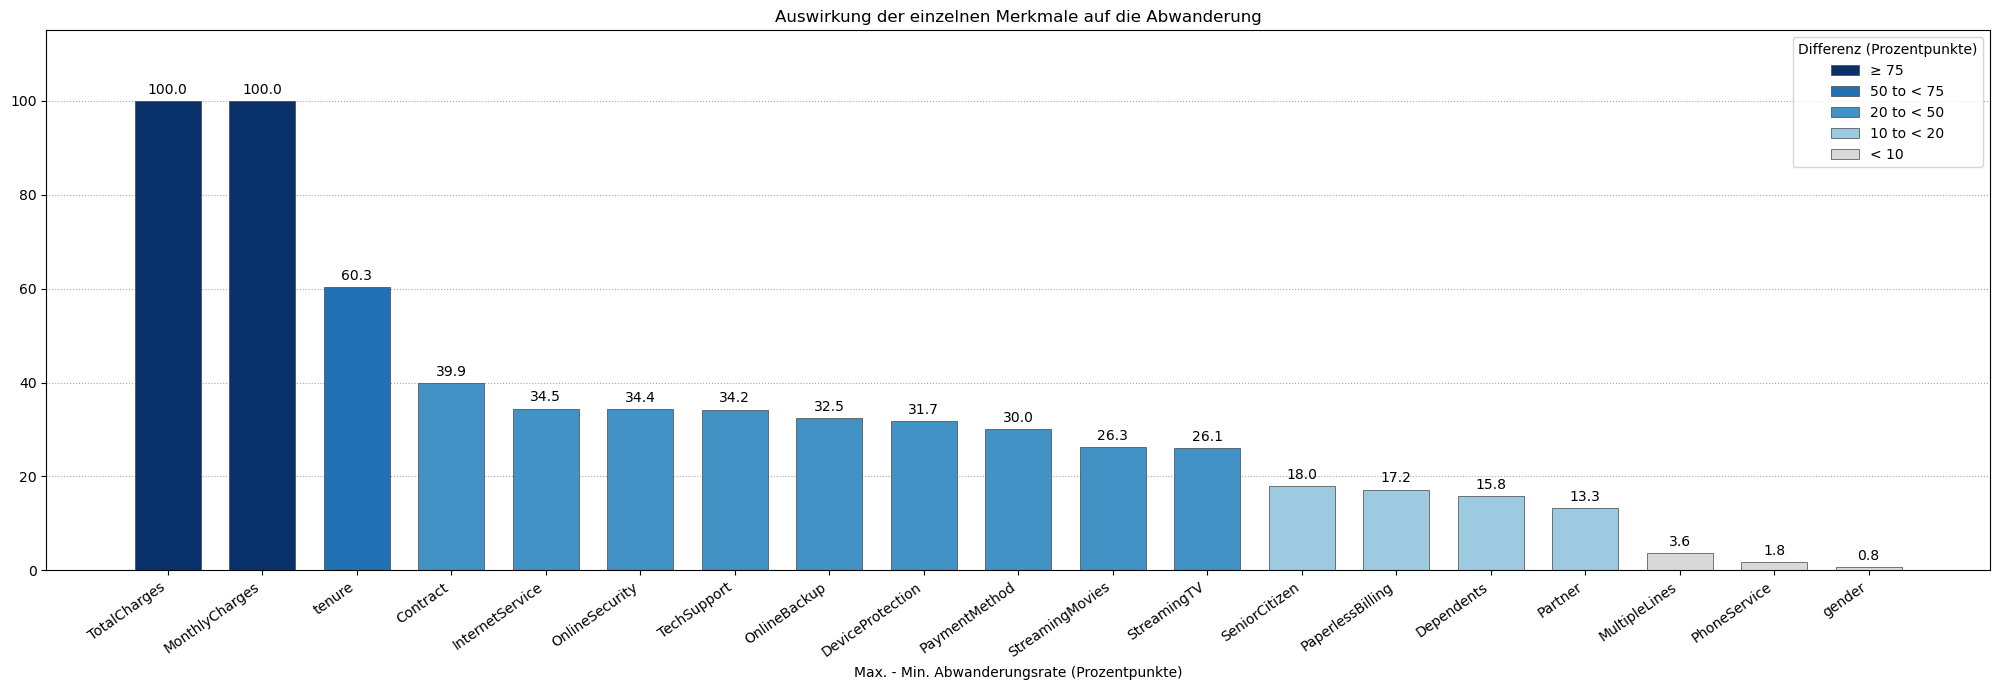

In [345]:
diff_s = pd.Series(diffs).sort_values()

diff_classes = [
    (75, "#08306b", "≥ 75"),
    (50, "#2171b5", "50 to < 75"),
    (20, "#4292c6", "20 to < 50"),
    (10, "#9ecae1", "10 to < 20"),
    (0,  "#d9d9d9", "< 10"),
]

plot_ranked_bars(
    values=pd.Series(diffs),
    classes=diff_classes,
    xlabel="Max. - Min. Abwanderungsrate (Prozentpunkte)",
    title="Auswirkung der einzelnen Merkmale auf die Abwanderung",
    filename=OUTPUT_Plots/"effect_features_on_churn_group.png",
    legend_title="Differenz (Prozentpunkte)",
    fmt="%.1f",
    min_xmax=10,
)

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<div class="explanation">
<h4 style="color:green;"> 2.4 Wir untersuchen den Zusammenhang Chi-Quadrat-Test <code class="code-orange">χ²</code> und <code class="code-orange">φ</code> (Korrelation) zwischen den Merkmalen und dem Zielmerkmal <span class="code-orange"> „Churn“ </span>:</h4>

<p class="explanation">
Bei zwei binären Variablen sind der Chi-Quadrat-Test und der Phi-Koeffizient mathematisch eng miteinander verbunden. 
</p>
<p class="explanation">Der Chi-Quadrat-Test eignet sich dazu, die statistische Signifikanz eines Zusammenhangs zu untersuchen. 
</p>
<p class="explanation">Der Phi-Koeffizient liefert zusätzlich ein standardisiertes Maß für dessen Stärke und Richtung.
</p>

<p class="explanation">
Für unsere Analyse sind beide Methoden nützlich: Der Chi-Quadrat-Test hilft bei der Beurteilung der statistischen Signifikanz, während der Phi-Koeffizient dabei hilft, die Stärke und Richtung des Zusammenhangs verständlich zu beschreiben.
</p>

In [346]:
gesucht_features_corr  = [col for col in df_neue.columns if col != "Churn"]

alpha = 0.01
ergebnisse = []

for feature in gesucht_features_corr :
    ct = pd.crosstab(df_neue[feature], df_neue["Churn"])
    chi2, p, dof, expected = chi2_contingency(ct)

    n = ct.values.sum()
    cramers_v = (chi2 / (n * (min(ct.shape) - 1))) ** 0.5

    ergebnisse.append({
        "feature": feature,
        "p_value": p,
        "cramers_v": round(cramers_v, 3),
        "min_expected": expected.min().round(1),
    })

ergebnisse = pd.DataFrame(ergebnisse).sort_values("p_value").reset_index(drop=True)
#print(ergebnisse)
# features without a significant relationship to Churn
ausgeschlossen_feature_chi  = ergebnisse.loc[ergebnisse["p_value"] >= alpha, "feature"].tolist()
gesuchten_feature_chi  = ergebnisse.sort_values("cramers_v",ascending=False).loc[ergebnisse["p_value"] < alpha, "feature"].tolist()

print("Ausgeschlossene Feature nach Chi-squared:", ausgeschlossen_feature_chi)
print("Gesuchte Featuresnach Chi-squared:", gesuchten_feature_chi)

Ausgeschlossene Feature nach Chi-squared: ['PhoneService', 'gender', 'TotalCharges']
Gesuchte Featuresnach Chi-squared: ['MonthlyCharges', 'Contract', 'tenure', 'OnlineSecurity', 'TechSupport', 'InternetService', 'PaymentMethod', 'OnlineBackup', 'DeviceProtection', 'StreamingMovies', 'StreamingTV', 'PaperlessBilling', 'Dependents', 'SeniorCitizen', 'Partner', 'MultipleLines']


<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<div class="explanation">
<h4 style="color:green;">Besondere Aufmerksamkeit bei der Interpretation des Chi-Quadrat-Tests <code class="code-orange">χ²</code>.</h4>

<p class="explanation">
Die Chi-Quadrat-Test <code class="code-orange">χ²</code> erklart die Zusammenhäng mit der Merkmale <code class="code-orange">MonthlyCharges</code> und <code class="code-orange">TotalCharges</code> falsch und Man  soll bei der Analyse besonders aufmerksam betrachtet werden.
</p>



In [347]:
hervorheben = ["MonthlyCharges", "TotalCharges"]

def highlight_rows(row):
    if row["feature"] in hervorheben:
        return ["background-color: yellow; color: red"] * len(row)
    return [""] * len(row)

display(ergebnisse.sort_values("cramers_v",ascending=False).style.apply(highlight_rows, axis=1))

,feature,p_value,cramers_v,min_expected
18,TotalCharges,0.585875,0.962000,0.300000
14,MonthlyCharges,0.000000,0.549000,0.300000
0,Contract,0.000000,0.410000,391.200000
3,tenure,0.000000,0.388000,13.300000
1,OnlineSecurity,0.000000,0.347000,404.000000
2,TechSupport,0.000000,0.343000,404.000000
4,InternetService,0.000000,0.322000,404.000000
5,PaymentMethod,0.000000,0.303000,404.300000
6,OnlineBackup,0.000000,0.292000,404.000000
7,DeviceProtection,0.000000,0.281000,404.000000


<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<h4 style="color:green;"> Ein rangiertes horizontales Balkendiagramm der corellationen für alle Merkmale gleichzeitig:</h4>


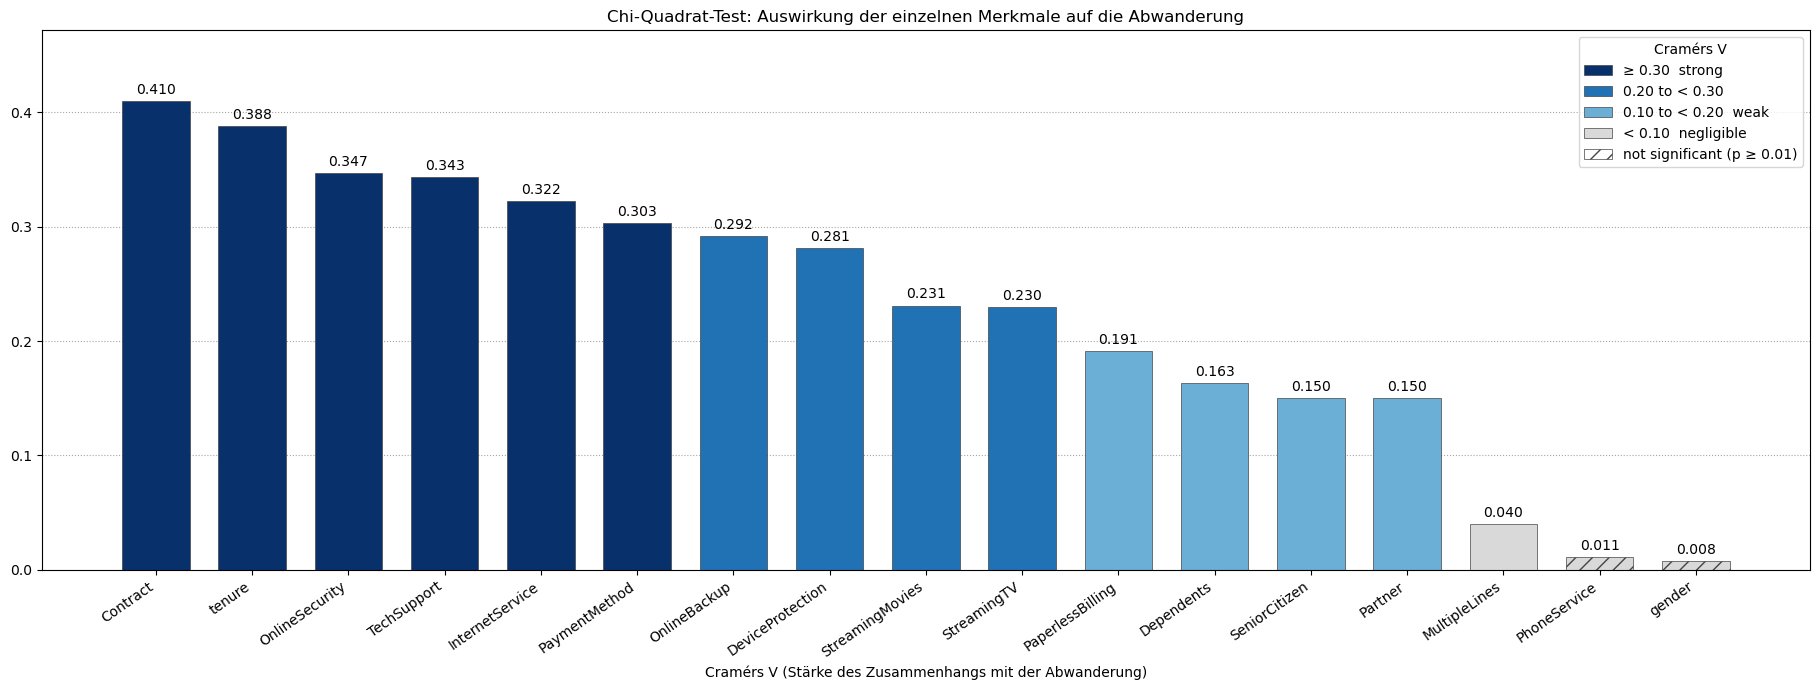

In [348]:
# only features where the chi-square test is valid (expected counts >= 5)
v_classes = [
    (0.30, "#08306b", "≥ 0.30  strong"),
    (0.20, "#2171b5", "0.20 to < 0.30"),
    (0.10, "#6baed6", "0.10 to < 0.20  weak"),
    (0.00, "#d9d9d9", "< 0.10  negligible"),
]

valid = ergebnisse[ergebnisse["min_expected"] >= 5]
nicht_signifikant = set(valid.loc[valid["p_value"] >= alpha, "feature"])

plot_ranked_bars(
    values=valid.set_index("feature")["cramers_v"],
    classes=v_classes,
    xlabel="Cramérs V (Stärke des Zusammenhangs mit der Abwanderung)",
    title="Chi-Quadrat-Test: Auswirkung der einzelnen Merkmale auf die Abwanderung",
    filename=OUTPUT_Plots/"effect_features_on_churn_chi2.png",
    legend_title="Cramérs V",
    fmt="%.3f",
    not_significant=nicht_signifikant,
    alpha=alpha,
    min_xmax=0.1,
)

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<div class="explanation">
  <h4 style="color:green;">2.4 Kategorische Merkmale in numerische Werte umwandeln</h4>

  <ul>
    <li>
      Wir unterscheiden zwischen <span class="key-point">binären kategorialen Merkmalen</span>
      und <span class="key-point">nicht-binären kategorialen Merkmalen</span>.
    </li>
    <li>
      Für binäre kategoriale Merkmale, wie <span class="code-orange">"Gender"</span>
      und <span class="code-orange">"Churn"</span>, verwenden wir eine
      <span class="code-orange">Label-Encoding</span>-Methode, bei der die Kategorien
      beispielsweise den Werten <span class="code-orange">0</span> und
      <span class="code-orange">1</span> zugeordnet werden.
    </li>
    <li>
      Für nicht-binäre kategoriale Merkmale, wie
      <span class="code-orange">"MultipleLines"</span> und
      <span class="code-orange">"PaymentMethod"</span>, wir die
      <span class="code-orange">One-Hot-Encoding</span> verwenden. 
    </li>
  </ul>
  <span class="key-point"> Wir bemerken, dass die nicht-binären kategorialen Merkmale nur 3 oder 4 Werte haben. Daher ist <span class="code-orange">One-Hot-Encoding</span> in der Regel die bessere Wahl für das Encoding (besser als <span class="code-orange">Target Encoding</span> mit oder ohne Weight) </span>

</div>


In [349]:
"""
bool_features    = [col for col in gesuchten_feature_chi if len(df_neue[col].unique()) == 2]
nonbool_features = [col for col in gesuchten_feature_chi if len(df_neue[col].unique()) > 2  and not is_numeric_dtype(df_neue[col])]
numeric_features = [col for col in gesuchten_feature_chi if df_neue[col].nunique() > 2 and is_numeric_dtype(df_neue[col])]

print("binären kategorialen Merkmalen:", bool_features)
print("nicht binären kategorialen Merkmalen:", 
      {f"{[name_feat for name_feat in nonbool_features]}",
      f"{[len(df_neue[name_feat].unique()) for name_feat in nonbool_features]}"} )
print("numericshe Merkmalen:", numeric_features)
"""

'\nbool_features    = [col for col in gesuchten_feature_chi if len(df_neue[col].unique()) == 2]\nnonbool_features = [col for col in gesuchten_feature_chi if len(df_neue[col].unique()) > 2  and not is_numeric_dtype(df_neue[col])]\nnumeric_features = [col for col in gesuchten_feature_chi if df_neue[col].nunique() > 2 and is_numeric_dtype(df_neue[col])]\n\nprint("binären kategorialen Merkmalen:", bool_features)\nprint("nicht binären kategorialen Merkmalen:", \n      {f"{[name_feat for name_feat in nonbool_features]}",\n      f"{[len(df_neue[name_feat].unique()) for name_feat in nonbool_features]}"} )\nprint("numericshe Merkmalen:", numeric_features)\n'

In [350]:
df_neue2 = df_neue[[element for element in gesuchten_feature_chi if is_numeric_dtype(df_neue[element])]]
    


In [351]:
number_ausgewahlte_features = 6  # choose it as your decision 
for feat in gesuchten_feature_chi:
    if feat not in df_neue2.columns and len(df_neue2.columns) <= number_ausgewahlte_features:
        df_neue2 = pd.concat([df_neue2, df[[feat]]], axis=1, join="inner")

df_neue2.head(100)

,MonthlyCharges,tenure,SeniorCitizen,Contract,OnlineSecurity,TechSupport,InternetService
0,29.85,1,0,Month-to-month,No,No,DSL
1,56.95,34,0,One year,Yes,No,DSL
2,53.85,2,0,Month-to-month,Yes,No,DSL
3,42.30,45,0,One year,Yes,Yes,DSL
4,70.70,2,0,Month-to-month,No,No,Fiber optic
...,...,...,...,...,...,...,...
95,78.95,12,0,Month-to-month,Yes,No,Fiber optic
96,66.85,71,0,One year,Yes,Yes,DSL
97,21.05,5,0,Month-to-month,No internet service,No internet service,No
98,21.00,52,0,Two year,No internet service,No internet service,No


<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<h2 style="color:green;">Die Funktion <code class="code-orange">encoddi()</code></h2>

<p class="explanation">
Die Funktion <code class="code-orange">encoddi()</code> wandelt kategoriale Merkmale in numerische Werte um, damit sie für die Datenanalyse und Machine Learning verwendet werden können. Dafür erstellt sie zunächst eine Kopie des DataFrames und unterteilt die Merkmale in drei Gruppen:
</p>

<ul class="explanation">
  <li><code class="code-orange">bool_feat</code>: Merkmale mit genau zwei unterschiedlichen Werten – kodiert mit <code class="code-orange">LabelEncoder()</code>.</li>
  <li><code class="code-orange">nonbool_feat</code>: Nicht numerische Merkmale mit mehr als zwei Werten – kodiert mit <code class="code-orange">OneHotEncoder()</code>.</li>
  <li><code class="code-orange">numeric_feat</code>: Numerische Merkmale mit mehr als zwei unterschiedlichen Werten – bleiben unverändert.</li>
</ul>

<p class="explanation">
Die verwendeten One-Hot-Encoder werden im Dictionary <code class="code-orange">encoders</code> gespeichert. Mit <code class="code-orange">verbose=True</code> werden die Merkmalsgruppen und Encoder ausgegeben. Am Ende gibt die Funktion den kodierten DataFrame zurück.
</p>

In [352]:
def encoddi(data_frame, verbose=False, return_encoders=False,drop_first=True):
    df = data_frame.copy()

    bool_feat    = [col for col in df.columns if len(df[col].unique()) == 2]
    
    nonbool_feat = [col for col in df.columns if len(df[col].unique()) > 2  
                    and not is_numeric_dtype(df[col])]
    
    numeric_feat = [col for col in df.columns if df[col].nunique() > 2 
                    and is_numeric_dtype(df[col])]

    for elem in bool_feat:
        oe = LabelEncoder()
        df[elem] = oe.fit_transform(df[elem])
    
    encoders = {}
    for elem in nonbool_feat:
        ohe = OneHotEncoder(drop="first" if drop_first else None,
                            sparse_output=False, dtype=int)
        encoded = ohe.fit_transform(df[[elem]])  

        encoded_df = pd.DataFrame(encoded,
                                  columns = ohe.get_feature_names_out([elem]), 
                                  index = df.index                        
                                 )
        df = pd.concat([df.drop(columns=elem), encoded_df], axis=1)
        encoders[elem] = ohe
    
    if verbose:
        print("bool_feat:    ", bool_feat)
        print("nonbool_feat: ", nonbool_feat)
        print("numeric_feat: ", numeric_feat)
        print(encoders)
        
    return df, encoders

<style>
.code-orange {
  color: #D19A66;
  background: none;
  font-style: italic;
}
.key-point {
  color: #6FBF9E;
}
.code-rot {
  color: #D9736B;
  background: none;
  font-weight: bold;
}
.explanation {
  color: #B5ADC2;
}
</style>

<h4 style="color:green;"><span class="code-orange">Segmentanalyse:</span>
  Kundengruppen mit erhöhtem Churn-Risiko identifizieren</span>
</h4>

<p class="explanation">
  <strong>Ziel:</strong> Zwei Kundensegmente identifizieren, bei denen die Abwanderungsrate (<code class="code-orange">Churn-Rate</code>) untersucht wird, um mögliche Risikogruppen zu erkennen.
</p>

<p class="explanation">
  <strong>Segment 1 – Neue Kunden mit Monatsvertrag:</strong>
  Dieses Segment umfasst Kunden mit einer Vertragslaufzeit von höchstens 12 Monaten (<code class="code-orange">tenure &lt;= 12</code>), die einen monatlich kündbaren Vertrag (<code class="code-orange">Month-to-month</code>) haben. Diese Kunden könnten besonders gefährdet sein, da sie noch nicht lange beim Unternehmen sind und flexibel kündigen können.
</p>

<p class="explanation">
  <strong>Segment 2 – Monatsvertrag mit hohen Kosten:</strong>
  Dieses Segment umfasst Kunden mit einem monatlich kündbaren Vertrag, deren monatliche Kosten mindestens dem 75. Perzentil entsprechen. Die Kostengrenze wird dynamisch über <code class="code-orange">quantile(0.75)</code> berechnet. Damit gehören Kunden mit den höchsten monatlichen Kosten (ungefähr die obersten 25 % aller Kunden nach Kosten) zur untersuchten Gruppe, sofern sie einen Monatsvertrag haben.
</p>

<p class="explanation">
  <strong>Auswertung:</strong> Für beide Segmente werden die <code class="code-orange">Kundenanzahl</code> und die <code class="code-orange">Churn-Rate</code> berechnet. Die Churn-Rate ergibt sich aus dem Mittelwert der binären Churn-Spalte und wird in Prozent angegeben.
</p>

<p class="explanation">
  <strong>Interpretation:</strong> Durch den Vergleich der Churn-Raten lässt sich untersuchen, ob neue Kunden mit Monatsvertrag oder Kunden mit hohen monatlichen Kosten häufiger abwandern. Die tatsächlichen Ergebnisse müssen anhand der berechneten Werte bewertet werden.
</p>

In [369]:
from itertools import combinations

df_risk,encoders = encoddi(df_neue, drop_first=False)       # every category keeps its column
df_risk = df_risk.loc[:, ~df_risk.T.duplicated()] 
features = df_risk.columns.drop(["Churn", "TotalCharges"], errors="ignore")


def hoch(col):
    """True for the 'high' customers of a feature:
    value 1 for binary columns, top 25 % (>= 75th percentile) otherwise."""
    if df_risk[col].nunique() == 2:
        return df_risk[col] == df_risk[col].max()
    return df_risk[col] >= df_risk[col].quantile(0.75)

segmente = []
for elem1, elem2 in combinations(features, 2):
    segment = df_risk[hoch(elem1) & hoch(elem2)]
    if len(segment) == 0:
        continue

    kundenanzahl = len(segment)

    segmente.append({
        "Segment": f"{elem1} mit {elem2}",
        "Kundenanzahl": kundenanzahl,
        "ChurnRate": round(segment["Churn"].mean() * 100, 2),
    })

# --- sort: Churn-Rate descending (primary), customer count descending (tie-break)
segmente = (
    pd.DataFrame(segmente)
      .sort_values(["ChurnRate", "Kundenanzahl"], ascending=[False, False])
      .reset_index(drop=True)
)

# --- reliable segments only, already in churn-rate order
tabelle = (
    segmente[segmente["Kundenanzahl"] >= 30]
      .head(20)
      .reset_index(drop=True)
)

latex = tabelle.to_latex(                           # <-- tabelle, not segmente
    index=False,
    escape=True,
    float_format="%.2f",
    column_format="p{9cm}rr",
    longtable=True,
    caption="Reliable risk segments (n $\\geq$ 30), sorted by churn rate",
    label="tab:risk-segments-reliable",
)

dokument = (
    "\\documentclass[a4paper,11pt]{article}\n"
    "\\usepackage[T1]{fontenc}\n"
    "\\usepackage[utf8]{inputenc}\n"
    "\\usepackage{booktabs}\n"
    "\\usepackage{longtable}\n"
    "\\begin{document}\n"
    + latex +
    "\\end{document}\n"
)

with open(REPORTS_FILES / "segmente_komplett.tex", "w", encoding="utf-8") as f:
    f.write(dokument)

print("Rows written:", len(tabelle), "->", REPORTS_FILES / "segmente_komplett.tex")

Rows written: 20 -> /Users/MacBookPro2012/PycharmProjects/BBQ/PCED-PCAD/StudyCase/Reports/segmente_komplett.tex


In [ ]:
from itertools import combinations

df_risk,encoders = encoddi(df_neue, drop_first=False)       # every category keeps its column
df_risk = df_risk.loc[:, ~df_risk.T.duplicated()] 
features = df_risk.columns.drop(["Churn", "TotalCharges"], errors="ignore")


def hoch(col):
    """True for the 'high' customers of a feature:
    value 1 for binary columns, top 25 % (>= 75th percentile) otherwise."""
    if df_risk[col].nunique() == 2:
        return df_risk[col] == df_risk[col].max()
    return df_risk[col] >= df_risk[col].quantile(0.75)


segmente = []
for elem1, elem2 in combinations(features, 2):
    segment = df_risk[hoch(elem1) & hoch(elem2)]
    if len(segment) == 0:                           # no customer in this combination
        continue

    segmente.append({"Segment": f"{elem1} mit {elem2}", 
                     "Kundenanzahl": kundenanzahl,
                     "ChurnRate": round(segment["Churn"].mean() * 100, 2),
    })
     

segmente = (pd.DataFrame(segmente).sort_values(["ChurnRate", "Kundenanzahl"], ascending=[False, False]).reset_index(drop=True)
)
# print every segment in descending order of the churn rate
for _, zeile in segmente.iterrows():
    print(f"\n{zeile['Segment']}")
    print(f"Kundenanzahl: {zeile['Kundenanzahl']}")
    print(f"Churn-Rate: {zeile['ChurnRate']:.2f}%")

# only reliable segments, highest churn rate first (segmente is already sorted)
tabelle = segmente[segmente["Kundenanzahl"] >= 30].head(20)
latex = segmente.to_latex(
    index=False,
    escape=True,                       # needed for the underscores in the segment names
    float_format="%.2f",
    column_format="p{9cm}rr",          # long names wrap; the numbers are right-aligned
    longtable=True,
    caption="All risk segments, sorted by churn rate",
    label="tab:risk-segments-all",
)

dokument = (
    "\\documentclass[a4paper,11pt]{article}\n"
    "\\usepackage[T1]{fontenc}\n"
    "\\usepackage[utf8]{inputenc}\n"
    "\\usepackage{booktabs}\n"
    "\\usepackage{longtable}\n"
    "\\begin{document}\n"
    + latex +
    "\\end{document}\n"
)

with open(REPORTS_FILES/"segmente_komplett.tex", "w", encoding="utf-8") as f:
    f.write(dokument)

print("Rows written:", len(segmente), "->", REPORTS_FILES/ "segmente_komplett.tex")


SeniorCitizen mit Contract_Month-to-month
Kundenanzahl: 870
Churn-Rate: 54.65%

InternetService_Fiber optic mit Contract_Month-to-month
Kundenanzahl: 870
Churn-Rate: 54.61%

OnlineBackup_No mit PaymentMethod_Electronic check
Kundenanzahl: 870
Churn-Rate: 53.92%

Contract_Month-to-month mit PaymentMethod_Electronic check
Kundenanzahl: 870
Churn-Rate: 53.73%

SeniorCitizen mit PaymentMethod_Electronic check
Kundenanzahl: 870
Churn-Rate: 53.37%

InternetService_Fiber optic mit PaymentMethod_Electronic check
Kundenanzahl: 870
Churn-Rate: 53.23%

TechSupport_No mit PaymentMethod_Electronic check
Kundenanzahl: 870
Churn-Rate: 53.18%

OnlineSecurity_No mit PaymentMethod_Electronic check
Kundenanzahl: 870
Churn-Rate: 53.17%

SeniorCitizen mit OnlineBackup_No
Kundenanzahl: 870
Churn-Rate: 52.77%

MonthlyCharges mit Contract_Month-to-month
Kundenanzahl: 870
Churn-Rate: 52.18%

DeviceProtection_No mit PaymentMethod_Electronic check
Kundenanzahl: 870
Churn-Rate: 52.06%

SeniorCitizen mit DevicePr

In [354]:
# identical columns in the encoded data
print(list(df_risk.columns[df_risk.T.duplicated(keep=False)]))

# segments that repeat the same numbers
print(segmente[segmente.duplicated(["Kundenanzahl", "ChurnRate"], keep=False)].head(20))
df_risk.info()
# keep InternetService_No, drop the six identical copies
doppelte = [c for c in df_risk.columns if c.endswith("_No internet service")]
df_risk = df_risk.drop(columns=doppelte)

# safety net: remove any other exactly identical column
df_risk = df_risk.loc[:, ~df_risk.T.duplicated()]

print(list(df_risk.columns[df_risk.T.duplicated(keep=False)]))

# segments that repeat the same numbers
print(segmente[segmente.duplicated(["Kundenanzahl", "ChurnRate"], keep=False)].head(20))
df_risk.info()

[]
                                               Segment  Kundenanzahl  \
16                 SeniorCitizen mit OnlineSecurity_No           870   
17          TechSupport_No mit Contract_Month-to-month           870   
18         OnlineBackup_No mit Contract_Month-to-month           870   
19     StreamingMovies_Yes mit Contract_Month-to-month           870   
47      InternetService_Fiber optic mit StreamingTV_No           870   
48   StreamingTV_Yes mit PaymentMethod_Electronic c...           870   
115                     gender mit DeviceProtection_No           870   
116  DeviceProtection_Yes mit PaymentMethod_Electro...           870   
151               MonthlyCharges mit MultipleLines_Yes           870   
152            DeviceProtection_Yes mit TechSupport_No           870   
156                          gender mit StreamingTV_No           870   
157             SeniorCitizen mit DeviceProtection_Yes           870   
169             OnlineSecurity_No mit OnlineBackup_Yes       

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<h4 style="color:green;">wir rufen die Funktion <code class="code-orange">encoddi()</code> mit der ausgewahlte Markmele zu encodierung:</h4>

In [355]:
df_neue_encoding, encoders = encoddi(df_neue2,True, True)

for feat, ohe in encoders.items():
    print(feat)
    print("  categories:        ", list(ohe.categories_[0]))
    print("  reference (dropped):", ohe.categories_[0][ohe.drop_idx_[0]])
    print("  new columns:       ", list(ohe.get_feature_names_out([feat])))

bool_feat:     ['SeniorCitizen']
nonbool_feat:  ['Contract', 'OnlineSecurity', 'TechSupport', 'InternetService']
numeric_feat:  ['MonthlyCharges', 'tenure']
{'Contract': OneHotEncoder(drop='first', dtype=<class 'int'>, sparse_output=False), 'OnlineSecurity': OneHotEncoder(drop='first', dtype=<class 'int'>, sparse_output=False), 'TechSupport': OneHotEncoder(drop='first', dtype=<class 'int'>, sparse_output=False), 'InternetService': OneHotEncoder(drop='first', dtype=<class 'int'>, sparse_output=False)}
Contract
  categories:         ['Month-to-month', 'One year', 'Two year']
  reference (dropped): Month-to-month
  new columns:        ['Contract_One year', 'Contract_Two year']
OnlineSecurity
  categories:         ['No', 'No internet service', 'Yes']
  reference (dropped): No
  new columns:        ['OnlineSecurity_No internet service', 'OnlineSecurity_Yes']
TechSupport
  categories:         ['No', 'No internet service', 'Yes']
  reference (dropped): No
  new columns:        ['TechSupport_N

In [356]:
"""
print(df_neue2.info())
print(df_neue2.head(10))
df_neue_encoding = encoddi(df_neue2,False)
print("="*50)
print(df_neue_encoding.info())
print(df_neue_encoding.head(10))
"""

'\nprint(df_neue2.info())\nprint(df_neue2.head(10))\ndf_neue_encoding = encoddi(df_neue2,False)\nprint("="*50)\nprint(df_neue_encoding.info())\nprint(df_neue_encoding.head(10))\n'

<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

<h3 style="color:green;">Schritt 1: X und y definieren</h3>

<p class="explanation">
<strong>Ziel:</strong> Die Merkmale <code class="code-orange">X</code> und die Zielvariable <code class="code-orange">y</code> für das Modell festlegen.
</p>
<p class="explanation">
Die vorherigen Kodierungsschritte haben die kategorialen Merkmale in numerische Werte umgewandelt. Außerdem müssen die Daten frei von fehlenden Werten sein, damit das Modell sie verarbeiten kann.
</p>

<p class="explanation">
Der Anteil der Kunden mit Churn liegt bei ungefähr <code class="code-orange">27 %</code>. Das zeigt, dass die Klassen unausgewogen sind (<span class="key-point">Class Imbalance</span>). Deshalb ist die Genauigkeit (<code class="code-orange">Accuracy</code>) allein kein zuverlässiges Bewertungsmaß.
</p>

In [357]:
y = df_neue["Churn"]
X = df_neue_encoding

print(X.dtypes.value_counts())  
print(X.isna().sum().sum())       
print(y.value_counts(normalize=True))


int64      10
float64     1
Name: count, dtype: int64
0
Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


<style>
  .code-orange {
    color: #D19A66;
    background: none;
    font-style: italic;
  }
  .key-point {
    color: #6FBF9E;
  }
  .code-rot {
    color: #D9736B;
    background: none;
    font-weight: bold;
  }
  .explanation {
    color: #B5ADC2;
  }
</style>

cSchritt 2:Trainings- und Testdaten aufteilen</span></h3>

<p class="explanation">
  <strong>Warum:</strong> Ein Modell passt immer besser zu seinen Trainingsdaten als zu neuen, unbekannten Daten. Nur Daten, die das Modell noch nie gesehen hat, zeigen, wie gut es auf neue Daten verallgemeinern kann.
</p>

<p class="explanation">
  <code class="code-orange">stratify=y</code> stellt sicher, dass der Churn-Anteil von 27 % in beiden Datensätzen gleich bleibt.
  <code class="code-orange">random_state</code> sorgt dafür, dass die Aufteilung reproduzierbar ist.
</p>

In [358]:
X_train, X_test, y_train, y_test = train_test_split(
                                   X, y, test_size=0.2, random_state=42, stratify=y)


In [359]:
def check_collinearity(X, r_limit=0.8, vif_limit=5):
    X = X.astype(float)

    # Level 1: identical columns and rank
    dup = X.columns[X.T.duplicated(keep=False)].tolist()
    design = sm.add_constant(X, has_constant="add")
    rank = np.linalg.matrix_rank(design.values)
    print(f"1) Identical columns: {dup if dup else 'none'}")
    print(f"   Rank {rank} of {design.shape[1]} columns (incl. constant)"
          f" -> {'OK' if rank == design.shape[1] else 'PERFECT COLLINEARITY'}")

    # Level 2: pairs with high correlation
    corr = X.corr()
    pairs = [(a, b, round(corr.loc[a, b], 3))
             for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
             if abs(corr.loc[a, b]) >= r_limit]
    print(f"2) Pairs with |r| >= {r_limit}: {pairs if pairs else 'none'}")

    # Level 3: VIF and condition number
    with np.errstate(divide="ignore", invalid="ignore"):
        vif = pd.Series(
            [variance_inflation_factor(design.values, i) for i in range(1, design.shape[1])],
            index=X.columns, name="VIF"
        ).sort_values(ascending=False)
    Z = (X - X.mean()) / X.std()
    print(f"3) Condition number (standardized): {np.linalg.cond(Z.values):.1f}"
          "  (above about 30 is a warning)")
    print(f"   VIF (limit {vif_limit}):")
    print(vif.round(2).to_string())
    return vif


vif = check_collinearity(X_train)

1) Identical columns: ['OnlineSecurity_No internet service', 'TechSupport_No internet service', 'InternetService_No']
   Rank 10 of 12 columns (incl. constant) -> PERFECT COLLINEARITY
2) Pairs with |r| >= 0.8: [('OnlineSecurity_No internet service', 'TechSupport_No internet service', np.float64(1.0)), ('OnlineSecurity_No internet service', 'InternetService_No', np.float64(1.0)), ('TechSupport_No internet service', 'InternetService_No', np.float64(1.0))]
3) Condition number (standardized): 251894797925558435660894830592.0  (above about 30 is a warning)
   VIF (limit 5):
OnlineSecurity_No internet service     inf
TechSupport_No internet service        inf
InternetService_No                     inf
MonthlyCharges                        9.26
InternetService_Fiber optic           4.87
Contract_Two year                     2.54
tenure                                2.29
Contract_One year                     1.59
TechSupport_Yes                       1.58
OnlineSecurity_Yes                   


<style>
.code-orange {
  color: #D19A66;
  background: none;
  font-style: italic;
}
.key-point {
  color: #6FBF9E;
}
.code-rot {
  color: #D9736B;
  background: none;
  font-weight: bold;
}
.explanation {
  color: #B5ADC2;
}
</style>

<h3 style="color:green;">Schritt 3: Numerische Spalten skalieren</span></h3>

<p class="explanation">
 <ul>
    <li>Die logistische Regression von scikit-learn verwendet Regularisierung. </li>
    <li>Dadurch werden Merkmale mit sehr unterschiedlichen Wertebereichen ungleich behandelt.</li>
    <li>Die Skalierung verbessert außerdem die Konvergenz des Modells und erleichtert den Vergleich der Koeffizienten.</li>
    <li>Der Scaler wird <strong>nur mit den Trainingsdaten</strong> angepasst. Würde er mit allen Daten angepasst, würden Informationen aus dem Testsatz in das Training einfließen (<code class="code-orange">Data Leakage</code>).</li>
</p>

In [360]:
num_cols = ["tenure", "MonthlyCharges"]
X_train, X_test = X_train.copy(), X_test.copy()

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])   
X_test[num_cols]  = scaler.transform(X_test[num_cols])        


<style>
.code-orange {
  color: #D19A66;
  background: none;
  font-style: italic;
}
.key-point {
  color: #6FBF9E;
}
.code-rot {
  color: #D9736B;
  background: none;
  font-weight: bold;
}
.explanation {
  color: #B5ADC2;
}
</style>

<h3 style="color:green;">Schritt 4: Modell trainieren</span></h3>

<p class="explanation">
  Das Modell berechnet zunächst einen Score
  <code class="code-orange">z = b0 + b1·x1 + …</code>
  und wandelt diesen mithilfe der Sigmoidfunktion in eine Wahrscheinlichkeit um:
  <code class="code-orange">1 / (1 + e<sup>−z</sup>)</code>.
</p>

<p class="explanation">
  Anschließend bestimmt das Modell die Koeffizienten so, dass die beobachteten Ergebnisse möglichst wahrscheinlich sind. Dieses Verfahren wird als <span class="key-point">Maximum-Likelihood-Schätzung</span> bezeichnet.
</p>

<p class="explanation">
  Der Parameter <code class="code-orange">max_iter=1000</code> erhöht die maximal zulässige Anzahl an Iterationen, damit das Modell ausreichend Zeit hat, eine Lösung zu finden und Konvergenzwarnungen zu vermeiden.
</p>


In [361]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [362]:
y_pred  = model.predict(X_test)                 # class 0/1 (threshold 0.5)
y_proba = model.predict_proba(X_test)[:, 1]     # probability of churn

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy: ", accuracy_score(y_test, y_pred))
print("Test AUC:      ", roc_auc_score(y_test, y_proba))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Train accuracy: 0.7946666666666666
Test accuracy:  0.7874911158493249
Test AUC:       0.8301880199408813
[[911 122]
 [177 197]]
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1033
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [363]:
"""
X_train_sm = sm.add_constant(X_train.astype(float))      # adds the intercept b0
full_model = sm.Logit(y_train, X_train_sm).fit()
print(full_model.summary())

ergebnis = pd.DataFrame({
    "coef": full_model.params,
    "odds_ratio": np.exp(full_model.params),
    "p_value": full_model.pvalues,
}).join(np.exp(full_model.conf_int()).rename(columns={0: "OR_low", 1: "OR_high"}))
print(ergebnis.sort_values("p_value"))
"""

'\nX_train_sm = sm.add_constant(X_train.astype(float))      # adds the intercept b0\nfull_model = sm.Logit(y_train, X_train_sm).fit()\nprint(full_model.summary())\n\nergebnis = pd.DataFrame({\n    "coef": full_model.params,\n    "odds_ratio": np.exp(full_model.params),\n    "p_value": full_model.pvalues,\n}).join(np.exp(full_model.conf_int()).rename(columns={0: "OR_low", 1: "OR_high"}))\nprint(ergebnis.sort_values("p_value"))\n'